In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE_DIR = Path.cwd()
FILE_A = BASE_DIR / "PokemonGO_Reliability_500_사람A.csv"
FILE_B = BASE_DIR / "PokemonGO_Reliability_500_사람B.csv"
OUTPUT_CSV = BASE_DIR / "PokemonGO_Krippendorff_Alpha_V1_2.csv"

ASPECTS = [f"A{i:02d}" for i in range(1, 9)]
VARIABLES = ASPECTS + ["G", "B01"]
VALID_SENTIMENT = {"-1", "0", "1", "9"}
VALID_BEHAVIOR = {"0", "1"}
MISSING_CODES = {"", "U", "NAN", "NONE", "NULL", "NA", "<NA>"}

print("A 파일:", FILE_A)
print("B 파일:", FILE_B)

A 파일: d:\vscode_project\포켓몬고\PokemonGO_Reliability_500_사람A.csv
B 파일: d:\vscode_project\포켓몬고\PokemonGO_Reliability_500_사람B.csv


In [2]:
def normalize(series: pd.Series) -> pd.Series:
    values = series.astype("string").str.strip().str.upper()
    values = values.replace({"1.0": "1", "0.0": "0", "-1.0": "-1", "9.0": "9"})
    return values.mask(values.isin(MISSING_CODES))


def load_coder(path: Path) -> pd.DataFrame:
    if not path.is_file():
        raise FileNotFoundError(f"코딩 CSV를 찾을 수 없습니다: {path}")
    data = pd.read_csv(path, dtype="string", encoding="utf-8-sig")
    needed = ["ID"] + VARIABLES
    missing_columns = [name for name in needed if name not in data.columns]
    if missing_columns:
        raise ValueError(f"{path.name}: 필요한 열이 없습니다: {missing_columns}")
    if data["ID"].isna().any() or data["ID"].duplicated().any():
        raise ValueError(f"{path.name}: ID 누락 또는 중복이 있습니다.")
    for name in VARIABLES:
        data[name] = normalize(data[name])
        allowed = VALID_BEHAVIOR if name == "B01" else VALID_SENTIMENT
        invalid = sorted(set(data[name].dropna()) - allowed)
        if invalid:
            raise ValueError(f"{path.name} / {name}: 허용되지 않은 값 {invalid}")
    return data[needed]

coder_a = load_coder(FILE_A)
coder_b = load_coder(FILE_B)
if set(coder_a["ID"]) != set(coder_b["ID"]):
    raise ValueError("사람 A와 B의 리뷰 ID 집합이 다릅니다.")

paired = coder_a.merge(coder_b, on="ID", suffixes=("_A", "_B"), validate="one_to_one")
print(f"동일 ID로 연결된 리뷰: {len(paired):,}건")
display(paired[["ID", "A01_A", "A01_B", "A08_A", "A08_B"]].head())

동일 ID로 연결된 리뷰: 500건


,ID,A01_A,A01_B,A08_A,A08_B
0,b27d1f9f-1a6e-4418-b197-d636b39e8bd8,9,9,9,9
1,3d206e46-6971-4302-a0f7-1e53d15e22ad,9,9,9,9
2,ea985b53-1d81-471c-bc8b-30849fb1e121,9,9,-1,-1
3,785a8a98-4529-44d2-8ea0-c250c0a52ff4,9,9,9,9
4,51ddaba4-ff5f-4c0e-969f-1161e8d0b08c,9,9,9,9


In [3]:
def krippendorff_nominal(x: pd.Series, y: pd.Series) -> dict:
    usable = x.notna() & y.notna()
    left = x[usable].reset_index(drop=True)
    right = y[usable].reset_index(drop=True)
    n = len(left)
    if n == 0:
        return {"유효쌍": 0, "일치건수": 0, "단순일치율": np.nan, "alpha": np.nan}
    agreements = int((left.to_numpy() == right.to_numpy()).sum())
    agreement_rate = agreements / n
    counts = pd.concat([left, right], ignore_index=True).value_counts()
    total = 2 * n
    expected_disagreement = 1 - (counts * (counts - 1)).sum() / (total * (total - 1))
    if np.isclose(expected_disagreement, 0):
        alpha = np.nan
    else:
        observed_disagreement = 1 - agreement_rate
        alpha = 1 - observed_disagreement / expected_disagreement
    return {"유효쌍": n, "일치건수": agreements, "단순일치율": agreement_rate, "alpha": alpha}


def to_presence(values: pd.Series) -> pd.Series:
    # 0(중립)도 해당 속성을 언급한 것이므로 출현(1)입니다.
    return values.map({"9": "0", "-1": "1", "0": "1", "1": "1"})

In [4]:
results = []
for name in VARIABLES:
    left = paired[f"{name}_A"]
    right = paired[f"{name}_B"]
    score = krippendorff_nominal(left, right)
    record = {
        "변수": name, "전체건수": len(paired),
        "유효쌍": score["유효쌍"],
        "U_등_결측제외": len(paired) - score["유효쌍"],
        "감성_일치건수": score["일치건수"],
        "감성_단순일치율": score["단순일치율"],
        "감성_alpha": score["alpha"],
    }
    if name in ASPECTS:
        presence = krippendorff_nominal(to_presence(left), to_presence(right))
        record.update({
            "출현_유효쌍": presence["유효쌍"],
            "출현_일치건수": presence["일치건수"],
            "출현_단순일치율": presence["단순일치율"],
            "출현_alpha": presence["alpha"],
        })
    results.append(record)

result = pd.DataFrame(results)
display(result.round(3))
result.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig", float_format="%.6f")
print("결과 저장:", OUTPUT_CSV)

,변수,전체건수,유효쌍,U_등_결측제외,감성_일치건수,감성_단순일치율,감성_alpha,출현_유효쌍,출현_일치건수,출현_단순일치율,출현_alpha
0,A01,500,480,20,452,0.942,0.890,480.0,460.0,0.958,0.910
1,A02,500,489,11,474,0.969,0.879,489.0,474.0,0.969,0.874
2,A03,500,479,21,465,0.971,0.887,479.0,467.0,0.975,0.901
3,A04,500,480,20,455,0.948,0.902,480.0,457.0,0.952,0.903
4,A05,500,498,2,490,0.984,0.855,498.0,490.0,0.984,0.854
5,A06,500,490,10,475,0.969,0.896,490.0,476.0,0.971,0.899
6,A07,500,478,22,453,0.948,0.860,478.0,458.0,0.958,0.884
7,A08,500,499,1,492,0.986,0.845,499.0,492.0,0.986,0.844
8,G,500,487,13,459,0.943,0.890,NaN,NaN,NaN,NaN
9,B01,500,500,0,498,0.996,0.831,NaN,NaN,NaN,NaN


결과 저장: d:\vscode_project\포켓몬고\PokemonGO_Krippendorff_Alpha_V1_2.csv


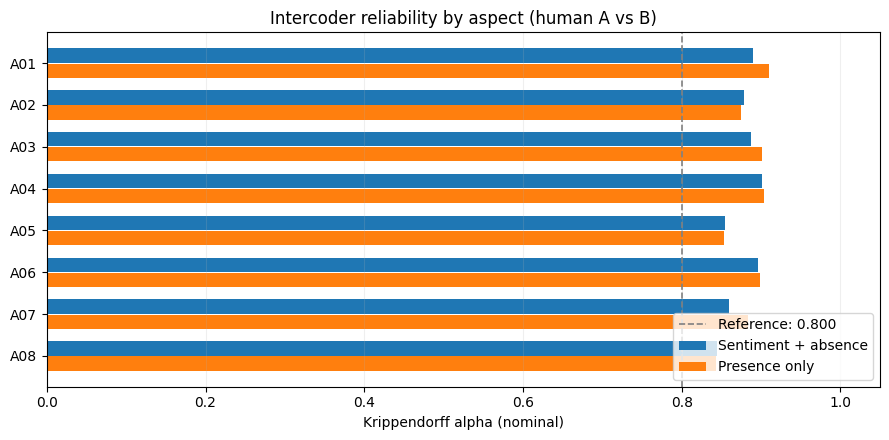

In [5]:
plot_data = result[result["변수"].isin(ASPECTS)].copy()
positions = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(positions - 0.18, plot_data["감성_alpha"], height=0.34, label="Sentiment + absence")
ax.barh(positions + 0.18, plot_data["출현_alpha"], height=0.34, label="Presence only")
ax.axvline(0.8, linestyle="--", linewidth=1.2, color="gray", label="Reference: 0.800")
ax.set_yticks(positions, plot_data["변수"])
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("Krippendorff alpha (nominal)")
ax.set_title("Intercoder reliability by aspect (human A vs B)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()